# Source-specific external forecasting

Compare pressure and timing errors separately for the five external sources.
Each entry averages the metrics of the 15 internally fitted fold models, and each
prediction is scored before averaging.

In [1]:
from pathlib import Path
import sys
import os
from datetime import datetime, timezone
os.environ.setdefault("LIQ_FINAL_DEVICE", os.environ.get("LIQ_DEVICE", "cpu"))
os.environ.setdefault("LIQ_DEVICE", os.environ["LIQ_FINAL_DEVICE"])
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "pyproject.toml").is_file() and (p / "src/dpi_evt").is_dir())
for directory in (ROOT / "src", ROOT / "external_validation", ROOT / "scripts"):
    if str(directory) not in sys.path:
        sys.path.insert(0, str(directory))
import numpy as np
import pandas as pd
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "font.family": "DejaVu Sans", "axes.grid": True, "grid.alpha": .2})
COLORS = {"DPI-EVT":"#246aac", "DPI-EVT +A":"#1b9e8a", "EVT-NeuralSSM":"#69788a",
          "Transformer +cummax":"#c17a24", "Transformer matched +A/crossing loss":"#8658a6",
          "GP prefix (linear + SE)":"#8469a5", "Threshold-projected Transformer/GBM":"#777777",
          "Time-warped Transformer/GBM":"#b685b3", "GBM horizon mixture":"#a66c20", "Cox PH":"#555555"}
TABLES = ROOT / "results/tables"
print("Executed:", datetime.now(timezone.utc).isoformat(timespec="seconds"))
print("Inputs: included aggregate tables and public external extracts")

Executed: 2026-11-06T14:07:03+00:00
Inputs: included aggregate tables and public external extracts


## Pressure and timing errors

curve_rmse


source,Adapazari,Christchurch,KFS-TCUA,KFS-TCUI,LEAP-2017
model,,,,,
DPI-EVT +A,0.2897,0.1870,0.3174,0.2258,0.1268
Transformer matched +A/crossing loss,0.3166,0.2470,0.2853,0.2309,0.1275
DPI-EVT +A/no reciprocal drift,0.2738,0.2028,0.2970,0.1616,0.1713
Threshold-projected Transformer/GBM,0.3040,0.2180,0.2816,0.2317,0.1237
GBM horizon mixture,NaN,NaN,NaN,NaN,NaN
Cox PH,NaN,NaN,NaN,NaN,NaN


onset_logmae


source,Adapazari,Christchurch,KFS-TCUA,KFS-TCUI,LEAP-2017
model,,,,,
DPI-EVT +A,0.5812,0.5342,1.3551,0.9445,0.8201
Transformer matched +A/crossing loss,1.0313,0.6171,1.7613,1.1408,0.7512
DPI-EVT +A/no reciprocal drift,0.7609,0.9041,1.9711,1.0941,1.2119
Threshold-projected Transformer/GBM,0.5322,0.3578,1.3813,1.4895,0.9691
GBM horizon mixture,0.5322,0.3578,1.3813,1.4895,1.0436
Cox PH,0.6152,0.3125,1.5717,0.9341,0.8658


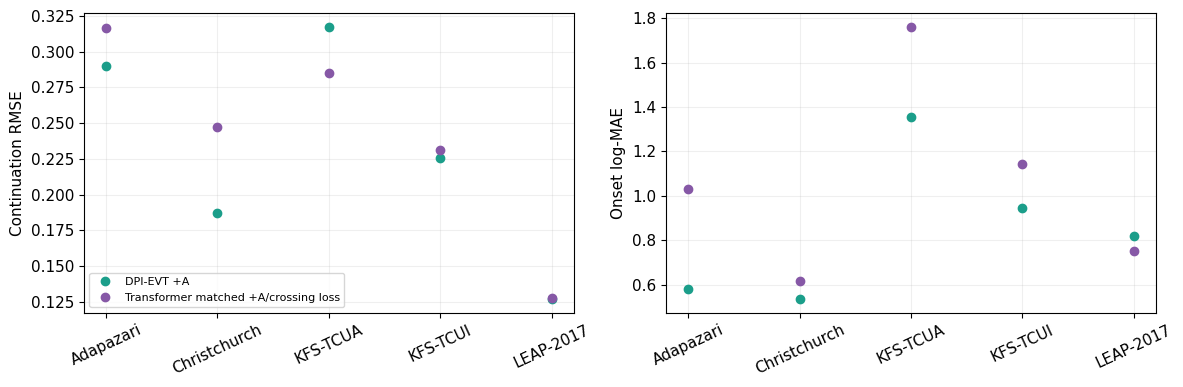

In [2]:
joint=pd.read_csv(TABLES/"joint_metrics.csv")
models=["DPI-EVT +A","Transformer matched +A/crossing loss","DPI-EVT +A/no reciprocal drift",
        "Threshold-projected Transformer/GBM","GBM horizon mixture","Cox PH"]
external=joint[joint.source.ne("internal") & joint.model.isin(models)]
for metric in ["curve_rmse","onset_logmae"]:
    print(metric)
    display(external.pivot(index="model",columns="source",values=metric).reindex(models).round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4))
for name in models[:2]:
    g=external[external.model.eq(name)].sort_values("source")
    axes[0].plot(g.source,g.curve_rmse,"o",color=COLORS[name],label=name)
    axes[1].plot(g.source,g.onset_logmae,"o",color=COLORS[name],label=name)
for ax,title in zip(axes,["Continuation RMSE","Onset log-MAE"]):
    ax.set(ylabel=title);ax.tick_params(axis="x",rotation=25)
axes[0].legend(fontsize=8);fig.tight_layout();plt.show()

## Source-conditional paired intervals

Resampling retains all 15 forecasts of each selected test. KFS-TCUA has a single event and therefore no timing interval.

In [3]:
ci=pd.read_csv(TABLES/"external_paired_bootstrap.csv")
display(ci[ci.reference.eq("DPI-EVT +A") & ci.comparator.eq("Transformer matched +A/crossing loss")][
    ["source","metric","ratio","ratio_lo","ratio_hi"]].round(4))
display(pd.read_csv(TABLES/"external_counts.csv"))

,source,metric,ratio,ratio_lo,ratio_hi
12,Adapazari,curve_rmse,0.9151,0.8512,0.9594
13,Adapazari,onset_logmae,0.5636,0.4422,0.7275
32,Christchurch,curve_rmse,0.7572,0.5078,0.8766
33,Christchurch,onset_logmae,0.8657,0.4968,2.2538
52,KFS-TCUA,curve_rmse,1.1125,1.0461,1.1847
53,KFS-TCUA,onset_logmae,0.7694,NaN,NaN
72,KFS-TCUI,curve_rmse,0.9782,0.9083,1.0754
73,KFS-TCUI,onset_logmae,0.8279,0.6571,1.0551
92,LEAP-2017,curve_rmse,0.9947,0.8578,1.4323
93,LEAP-2017,onset_logmae,1.0917,0.8083,1.6206


,source,tests,curve_tests,events,known_non_events,unresolved
0,Adapazari,54,53,46,0,8
1,Christchurch,21,20,15,0,6
2,KFS-TCUA,14,14,1,0,13
3,KFS-TCUI,20,20,20,0,0
4,LEAP-2017,18,18,17,0,1


## Recompute predictions using authorized fitted models

In [4]:
RECOMPUTE_EXTERNAL = False
if RECOMPUTE_EXTERNAL:
    from dpi_evt.experiments.final_run import notebook_run
    from extval.final_run import ExternalRun,summarize_external
    run=notebook_run(ROOT)
    raw,per_test=ExternalRun(run).evaluate()
    display(summarize_external(raw))
else:
    print("Source summaries loaded. Set RECOMPUTE_EXTERNAL=True to run the fitted local models.")

Source summaries loaded. Set RECOMPUTE_EXTERNAL=True to run the fitted local models.
